# Apprenez une heuristique pour le Go

Dans ce **TP noté**, vous devrez déployer des methodes d'apprentissage automatique permettant d'évaluer la qualité de plateaux de GO.

Pour cela, vous disposerez de 21854 exemples de plateau de Go, tous générés par `gnugo` après quelques coups contre lui même avec un niveau de difficulté de 0. Par chaque plateau, nous avons lancé 100 matchs de gnugo contre lui même, toujours avec un niveau 0, et compté le nombre de victoires de noir et de blanc depuis ce plateau.

A noter, chaque "rollout" (un rollout et un déroulement possible du match depuis le plateau de référence) correspond à des mouvements choisis aléatoirement parmis les 10 meilleurs mouvements possibles, en biasant le choix aléatoire par la qualité prédite du mouvement par gnugo (les meilleurs mouvements ont une plus forte probabilité d'être tirés).

Les données dont vous disposez sont brutes. Ce sera à vous de proposer un format adéquat pour utiliser ces données en entrée de votre réseau neuronal.


## Comment sera évalué votre modèle ?

Nous vous fournirons 6h avant la date de rendu un nouveau fichier contenant 1000 nouveaux exemples, qui ne contiendront pas les champs `black_wins`, `white_wins`, `black_points` et `white_points`. Vous devrez laisser, dans votre dépot de projet (votre dépot GIT sous un sous-répertoire ML) un fichier texte nommé `my_predictions.txt` ayant une prédiction par ligne (un simple flottant) qui donnera, dans le même ordre de la liste des exemples les scores que vous prédisez pour chacune des entrées du fichier que nous vous aurons donné. ** Les scores seront donnés sous forme d'un flottant, entre 0 et 1, donnant la probabilité de victoire de noir sur le plateau considéré **. Il faudra laisser, dans votre feuille notebook (voir tout en dessous) la cellule Python qui aura créé ce fichier, pour que l'on puisse éventuellement refaire vos prédictions.

Bien entendu, vous nous rendrez également votre feuille jupyter **sous deux formats**, à la fois le fichier `.ipynb` et le fichier `.html` nous permettant de lire ce que vous avez fait, sans forcément relancer la feuille. Nous prendrons en compte les résultats obtenus sur les prédictions mais aussi le contenu de vos notebooks jupyter.

### Comment sera noté ce TP ?

**Il s'agit d'un TP noté (et non pas d'un projet), donc il ne faudra pas y passer trop de temps**. Nous attendons des prédictions correctes mais surtout des choix justifiés dans la feuille. Votre feuille notebook sera le plus important pour la notation (n'hésitez pas à mettre des cellules de texte pour expliquer pourquoi vous avez été amenés à faire certains choix). Ainsi, il serait bien d'avoir, par exemple, les données (graphiques ou autre) qui permettent de comprendre comment vous avez évité l'overfitting.

Le fichier de vos prédiction sera évalué en se basant sur la qualité de vos prédictions. Nous mesurerons par exemple (juste pour vous donner une idée) le nombre d'exemples dont votre prédiction donnera la bonne valeur à 5%, 10%, 20%, 35%, 50% pour estimer sa qualité.


## Mise en route !

Voyons  comment lire les données


In [1]:
# Import du fichier d'exemples

def get_raw_data_go():
    ''' Returns the set of samples from the local file or download it if it does not exists'''
    import gzip, os.path
    import json

    raw_samples_file = "samples-8x8.json.gz"

    if not os.path.isfile(raw_samples_file):
        print("File", raw_samples_file, "not found, I am downloading it...", end="")
        import urllib.request
        urllib.request.urlretrieve ("https://www.labri.fr/perso/lsimon/static/inge2-ia/samples-8x8.json.gz", "samples-8x8.json.gz")
        print(" Done")

    with gzip.open("samples-8x8.json.gz") as fz:
        data = json.loads(fz.read().decode("utf-8"))
    return data

data = get_raw_data_go()
print("We have", len(data),"examples")

We have 41553 examples


## Compréhension des données de chaque entrée

Voici une description de chaque exemple

In [2]:
def summary_of_example(data, sample_nb):
    ''' Gives you some insights about a sample number'''
    sample = data[sample_nb]
    print("Sample", sample_nb)
    print()
    print("Données brutes en format JSON:", sample)
    print()
    print("The sample was obtained after", sample["depth"], "moves")
    print("The successive moves were", sample["list_of_moves"])
    print("After these moves and all the captures, there was black stones at the following position", sample["black_stones"])
    print("After these moves and all the captures, there was white stones at the following position", sample["white_stones"])
    print("Number of rollouts (gnugo games played against itself from this position):", sample["rollouts"])
    print("Over these", sample["rollouts"], "games, black won", sample["black_wins"], "times with", sample["black_points"], "total points over all this winning games")
    print("Over these", sample["rollouts"], "games, white won", sample["white_wins"], "times with", sample["white_points"], "total points over all this winning games")
 
summary_of_example(data,19)

Sample 19

Données brutes en format JSON: {'depth': 18, 'list_of_moves': ['E5', 'D3', 'C4', 'F2', 'B5', 'C3', 'B3', 'F4', 'F5', 'C2', 'G5', 'G4', 'H4', 'D4', 'D5', 'G3', 'B2', 'H3'], 'black_stones': ['B5', 'D5', 'E5', 'F5', 'G5', 'C4', 'H4', 'B3', 'B2'], 'white_stones': ['D4', 'F4', 'G4', 'C3', 'D3', 'G3', 'H3', 'C2', 'F2'], 'rollouts': 100, 'black_wins': 99, 'black_points': 1798.0, 'white_wins': 1, 'white_points': 10.0}

The sample was obtained after 18 moves
The successive moves were ['E5', 'D3', 'C4', 'F2', 'B5', 'C3', 'B3', 'F4', 'F5', 'C2', 'G5', 'G4', 'H4', 'D4', 'D5', 'G3', 'B2', 'H3']
After these moves and all the captures, there was black stones at the following position ['B5', 'D5', 'E5', 'F5', 'G5', 'C4', 'H4', 'B3', 'B2']
After these moves and all the captures, there was white stones at the following position ['D4', 'F4', 'G4', 'C3', 'D3', 'G3', 'H3', 'C2', 'F2']
Number of rollouts (gnugo games played against itself from this position): 100
Over these 100 games, black won 9

## Données en entrée et en sortie de votre modèle final

Même si en interne, votre modèle va manipuler des tenseurs en numpy, vous devrez construire une boite noire qui prendra en entrée les données dans le style du JSON ci-dessous. Typiquement, vous aurez le même genre de fichier avec seulement les champs `black_stones`, `white_stones`, `depth` et `list_of_moves` de renseignées. Vous devrez utiliser ces champs, dont notemment les coordonnées des pierres noires et blanches et donner le pourcentage de chance pour noir de gagner depuis cette position.

Ainsi, pour l'exemple `i` :
- Vous pourrez prendez en entree `data[i]["black_stones"]` et `data[i]["white_stones"]` (vous pouvez, si vous le souhaitez, prendre en compte également `list_of_moves` ou tout autre donnée que vous calculerez vous-même (mais qui ne se basera évidemment pas sur les données que vous n'aurez pas lors de l'évaluation).
- Vous devrez prédire simplement `data[i]["black_wins"]/data[i]["rollouts"]` en float (donc une valeur entre 0 et 1).

Encore une fois, **attention** : en interne, il faudra absolument construire vos données formattées en matrices numpy pour faire votre entrainement. On vous demande juste ici d'écrire comment vous faites ces transformations, pour comprendre ce que vous avez décidé de mettre en entrée du réseau.

Voici par exemple le modèle de la fonction qui pourra être appelée, au final :


In [17]:
_loaded_model = None

def position_predict(sample,
                     model_path="model_mse.pth",
                     device=None):
    global _loaded_model

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    if _loaded_model is None:
        _loaded_model = GoNet()
        _loaded_model.load_state_dict(
            torch.load(model_path, map_location=device)
        )
        _loaded_model.to(device)
        _loaded_model.eval()

    board = sample_to_board(sample)

    t = torch.tensor(board).unsqueeze(0).to(device)

    with torch.no_grad():
        return _loaded_model(t).item()

def create_result_file(newdata):
    resultat  = [position_predict(sample,model_path="model_bce.pth") for sample in newdata]
    with open("my_predictions.txt", "w") as f:
         for p in resultat:
            f.write(str(p)+"\n")


The CDF curve shows that black has more chances to win, globally


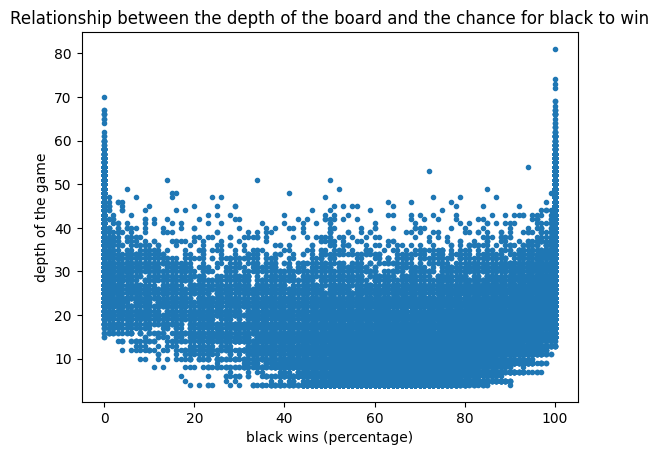

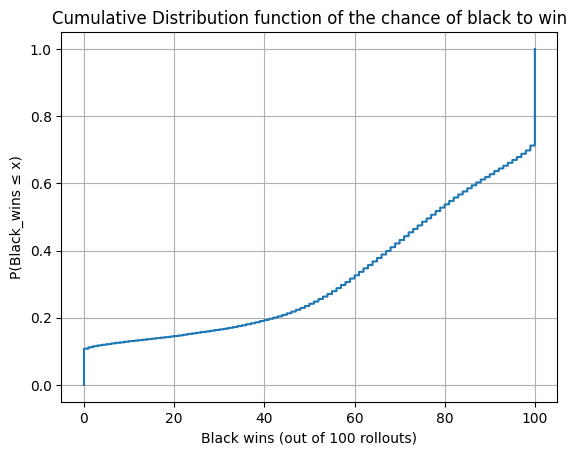

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.title("Relationship between the depth of the board and the chance for black to win")
plt.plot([sample["black_wins"] for sample in data],[sample["depth"] for sample in data], '.')
plt.xlabel("black wins (percentage)")
plt.ylabel("depth of the game")


# Cumulative Distribution function of the chance of black to win
cdf_wins = sorted([sample["black_wins"] for sample in data])
plt.figure()
plt.plot(cdf_wins,[x/len(cdf_wins) for x in range(len(cdf_wins))])
plt.grid()
plt.title("Cumulative Distribution function of the chance of black to win")
plt.ylabel("P(Black_wins ≤ x)")
plt.xlabel("Black wins (out of 100 rollouts)")
print("The CDF curve shows that black has more chances to win, globally")

# First steps: transform all the data into numpy arrays to feed your neural network

Advices:
- do not use only a 9x9 matrix as input. Use at least two planes to encode the board. One plane for black and one plane for white (typically with a 1 if there is a black stone for the first plane and with a 1 if there is a white stone for the second plane). The dimension of an input should be at least `[2,9,9]`. In Torch, the Conv2d method needs inputs as `[NBatch, Channels, H, W]`.
- consider to enrich your dataset with all symmetries and rotations. You should be able to multiply the number of samples to consider: any rotation of the board should have the same score, right?. You can use `np.rot90` to rotate your boards be beware of the dimensions (the channel is not the last dimension), so you may want to use `np.moveaxis()` to force the channels to be the last dimension, then call it again to make it the second one.
- what should happen on the score if you switch the colors? To know which player has to play next, you can check, for a sample, the parity of the length of the list `data[i]["list_of_moves"]` (an odd length list would mean that white is the next player. An even length list means that black has to play).
- work on enlarging and preparing your data only once. Once all you input data is setup as a big Numpy matrix, you may want to save it for speeding up everything. You can use, for instance `numpy.rot90()` and `numpy.flipud()` to generate all the symmetries



In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

def name_to_coord(s): 
    assert s != "PASS"
    indexLetters = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4, 'F':5, 'G':6, 'H':7}

    col = indexLetters[s[0]]
    lin = int(s[1:]) - 1
    return col, lin

def sample_to_board(sample):
     """                                                                        
     Encode un exemple en matrice [2, 8, 8]
     Channel 0 = pierres noires, Channel 1 = pierres blanches                   
     """                                                                        
     board = np.zeros((2, 8, 8), dtype=np.float32)                              
     for s in sample["black_stones"]:                                           
         c, l = name_to_coord(s)
         board[0, l, c] = 1.0                                                   
     for s in sample["white_stones"]:
         c, l = name_to_coord(s)                                                
         board[1, l, c] = 1.0
     return board

def augment_data(X, y):
    """                                                                        
    Multiplie les données par 16 :
    - 4 rotations × 2 retournements = 8 symétries géométriques                 
    - x 2 pour l'échange noir/blanc (score devient 1 - y)                      
    """                                                                        
    Xs, ys = [], []                                                            
    for k in range(4): # Rotation                                          
        Xr = np.rot90(X, k=k, axes=(2, 3))
        for flip in [False, True]: # Symétrie horizontal              
            Xf = np.flip(Xr, axis=2).copy() if flip else Xr.copy()             
            Xs.append(Xf)                                                      
            ys.append(y)                                                       
            Xswap = Xf[:, [1, 0], :, :] # Inversion blanc et noir             
            Xs.append(Xswap.copy())                                            
            ys.append(1.0 - y)                                                 
                                                                                 
    return np.concatenate(Xs, axis=0), np.concatenate(ys, axis=0) 

X_raw = np.array([sample_to_board(s) for s in data], dtype=np.float32)
y_raw = np.array([s["black_wins"] / s["rollouts"] for s in data], dtype=np.float32)                                          

X_aug, y_aug = augment_data(X_raw, y_raw)   

X_train, X_val, y_train, y_val = train_test_split(
    X_aug, y_aug, test_size=0.33, random_state=10                              
) 

print("X shape:", X_raw.shape)                           
print("y shape:", y_raw.shape)   
print("Après augmentation — X:", X_aug.shape, "Y:", y_aug.shape)
print("Train:", X_train.shape, "Val:", X_val.shape)

X shape: (41553, 2, 8, 8)
y shape: (41553,)
Après augmentation — X: (664848, 2, 8, 8) Y: (664848,)
Train: (445448, 2, 8, 8) Val: (219400, 2, 8, 8)


# Second steps: build your neural network and train it

Don't forget to check overfitting, ...

*advices* :
- you may need to use some of the `torch.nn` layers: `Linear`, `Conv2d`, `ReLU`, `LeakyReLU`, `BatchNorm2d`, `Flatten`, `Dropout`... But you can of course first build a very simple one (and just pick some of them)...
- if you use convolution layers, be sure **not to downsize your board**. Applying a filter should keep the original size of the board (9x9), otherwise you would somehow forget the stones on the borders
- you will use like 33% of your input sample for validation. However, the final goal is to score new data that will be given in addition to the actual data. So, you should use the 33% splitting rule to set up your network architecture and, once you fixed it, you should train your final model on the whole set of data, crossing your fingers that it will generalize well.
- Warning: if you run a few epoch, and run it again for some more epochs, it will not reset the weights and the biases of your neural network. It's good news because you can add more and more epochs to your model, but be careful about the training/test sets (do split your sets before you initialize your model). Or you will be breaking your validation/training partition!


In [6]:
import torch
import torch.nn as nn

class GoNet(nn.Module):                                                        
      def __init__(self):
          super().__init__()                                                     
          self.features = nn.Sequential(                                         
              nn.Conv2d(2, 64, kernel_size=3, padding=1),
              nn.BatchNorm2d(64),                                                
              nn.ReLU(),
                                                                                 
              nn.Conv2d(64, 128, kernel_size=3, padding=1),                      
              nn.BatchNorm2d(128),
              nn.ReLU(),                                                         
                  
              nn.Conv2d(128, 128, kernel_size=3, padding=1),
              nn.BatchNorm2d(128),
              nn.ReLU(),                                                         
   
              nn.Conv2d(128, 64, kernel_size=3, padding=1),                      
              nn.BatchNorm2d(64),
              nn.ReLU(),
          )                                                                      
          self.classifier = nn.Sequential(
              nn.Flatten(),                                                      
              nn.Linear(64 * 8 * 8, 256),
              nn.ReLU(),
              nn.Dropout(0.3),                                                   
              nn.Linear(256, 64),
              nn.ReLU(),                                                         
              nn.Linear(64, 1),
              nn.Sigmoid()
          )                                                                      
   
      def forward(self, x):                                                      
          x = self.features(x)
          return self.classifier(x).squeeze(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    ),
    batch_size=4096,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32)
    ),
    batch_size=4096
)

Epoch  1 | Train: 0.0602 | Val: 0.0341
Epoch  2 | Train: 0.0325 | Val: 0.0349
Epoch  3 | Train: 0.0305 | Val: 0.0270
Epoch  4 | Train: 0.0283 | Val: 0.0291
Epoch  5 | Train: 0.0266 | Val: 0.0289
Epoch  6 | Train: 0.0258 | Val: 0.0254
Epoch  7 | Train: 0.0256 | Val: 0.0259
Epoch  8 | Train: 0.0251 | Val: 0.0293
Epoch  9 | Train: 0.0252 | Val: 0.0270
Epoch 10 | Train: 0.0244 | Val: 0.0243
Epoch 11 | Train: 0.0238 | Val: 0.0260
Epoch 12 | Train: 0.0241 | Val: 0.0260
Epoch 13 | Train: 0.0243 | Val: 0.0258
Epoch 14 | Train: 0.0228 | Val: 0.0254
Epoch 15 | Train: 0.0204 | Val: 0.0228
Epoch 16 | Train: 0.0203 | Val: 0.0231
Epoch 17 | Train: 0.0204 | Val: 0.0227
Epoch 18 | Train: 0.0197 | Val: 0.0238
Epoch 19 | Train: 0.0199 | Val: 0.0241
Epoch 20 | Train: 0.0197 | Val: 0.0230
Epoch 21 | Train: 0.0190 | Val: 0.0245
Epoch 22 | Train: 0.0172 | Val: 0.0252
Epoch 23 | Train: 0.0167 | Val: 0.0220
Epoch 24 | Train: 0.0164 | Val: 0.0231
Epoch 25 | Train: 0.0164 | Val: 0.0255
Epoch 26 | Train: 0.0162 

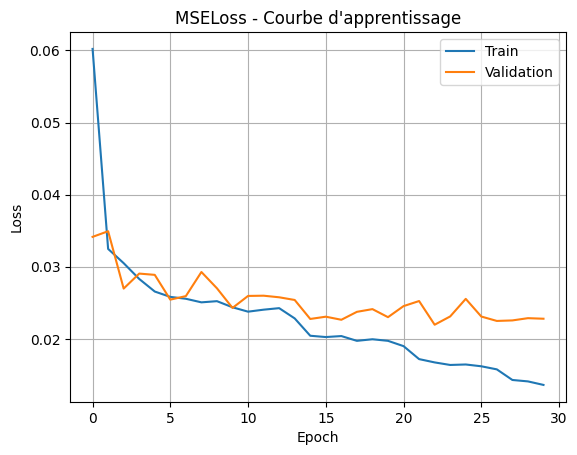

In [8]:
# Modèle avec MSE Loss function

model_mse = GoNet().to(device)
optimizer_mse = torch.optim.Adam(
    model_mse.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)
criterion_mse = nn.MSELoss()

scheduler_mse = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mse,
    patience=3,
    factor=0.5
)

train_losses_mse, val_losses_mse = [], []

for epoch in range(30):
    model_mse.train()
    tl = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer_mse.zero_grad()
        loss = criterion_mse(model_mse(xb), yb)
        loss.backward()
        optimizer_mse.step()

        tl += loss.item() * len(xb)

    tl /= len(X_train)
    train_losses_mse.append(tl) 

    model_mse.eval()
    vl = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            vl += criterion_mse(model_mse(xb), yb).item() * len(xb) # On multiplie par la taille du batch pour sommer correctement les loss ( les batches n'ont pas tous la même taille )

    vl /= len(X_val)
    val_losses_mse.append(vl)

    scheduler_mse.step(vl)

    print(f"Epoch {epoch+1:2d} | Train: {tl:.4f} | Val: {vl:.4f}")

plt.figure()
plt.plot(train_losses_mse, label="Train")
plt.plot(val_losses_mse, label="Validation")
plt.title("MSELoss - Courbe d'apprentissage")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

torch.save(model_mse.state_dict(), "model_mse.pth") 

Epoch  1 | Train: 0.4876 | Val: 0.4123
Epoch  2 | Train: 0.4121 | Val: 0.4034
Epoch  3 | Train: 0.4043 | Val: 0.4001
Epoch  4 | Train: 0.3978 | Val: 0.4047
Epoch  5 | Train: 0.3965 | Val: 0.3971
Epoch  6 | Train: 0.3920 | Val: 0.3887
Epoch  7 | Train: 0.3905 | Val: 0.3917
Epoch  8 | Train: 0.3864 | Val: 0.3873
Epoch  9 | Train: 0.3862 | Val: 0.3934
Epoch 10 | Train: 0.3842 | Val: 0.3919
Epoch 11 | Train: 0.3818 | Val: 0.3857
Epoch 12 | Train: 0.3832 | Val: 0.3896
Epoch 13 | Train: 0.3803 | Val: 0.3949
Epoch 14 | Train: 0.3798 | Val: 0.3878
Epoch 15 | Train: 0.3792 | Val: 0.3995
Epoch 16 | Train: 0.3709 | Val: 0.3817
Epoch 17 | Train: 0.3686 | Val: 0.3861
Epoch 18 | Train: 0.3690 | Val: 0.3801
Epoch 19 | Train: 0.3675 | Val: 0.3918
Epoch 20 | Train: 0.3677 | Val: 0.3875
Epoch 21 | Train: 0.3676 | Val: 0.3888
Epoch 22 | Train: 0.3668 | Val: 0.3860
Epoch 23 | Train: 0.3599 | Val: 0.3832
Epoch 24 | Train: 0.3586 | Val: 0.3846
Epoch 25 | Train: 0.3576 | Val: 0.3840
Epoch 26 | Train: 0.3568 

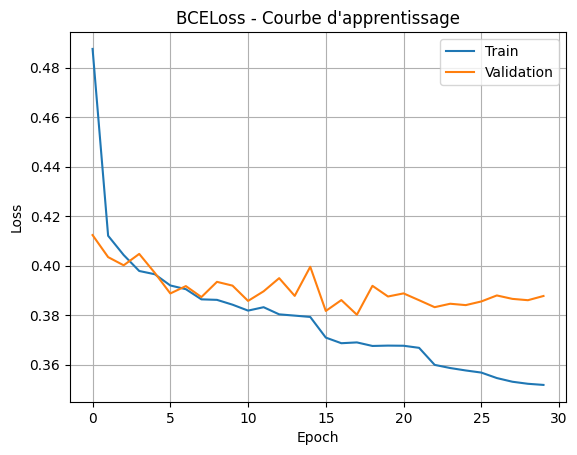

In [9]:
# Modèle avec BCE Loss function

model_bce = GoNet().to(device)

optimizer_bce = torch.optim.Adam(
    model_bce.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion_bce = nn.BCELoss()

scheduler_bce = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_bce,
    patience=3,
    factor=0.5
)

train_losses_bce, val_losses_bce = [], []

for epoch in range(30):
    model_bce.train()
    tl = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device) 

        optimizer_bce.zero_grad()
        loss = criterion_bce(model_bce(xb), yb)
        loss.backward()
        optimizer_bce.step()

        tl += loss.item() * len(xb) # On multiplie par la taille du batch pour sommer correctement les loss ( les batches n'ont pas tous la même taille )

    tl /= len(X_train) 

    model_bce.eval()
    vl = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            vl += criterion_bce(model_bce(xb), yb).item() * len(xb)

    vl /= len(X_val)

    scheduler_bce.step(vl)

    train_losses_bce.append(tl)
    val_losses_bce.append(vl)

    print(f"Epoch {epoch+1:2d} | Train: {tl:.4f} | Val: {vl:.4f}")

plt.figure()
plt.plot(train_losses_bce, label="Train")
plt.plot(val_losses_bce, label="Validation")
plt.title("BCELoss - Courbe d'apprentissage")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

torch.save(model_bce.state_dict(), "model_bce.pth")


# Last step

Prepare your model to predict the set of new data to predict, you will have only 6 hours to push your predictions.

(may be you would like to express, when guessing the percentage of wins for blacks, that it should reflect the fact that this score should be the same for all the symmetries you considered)...

In [14]:
import urllib.request
import os
import gzip
import json

sample_gz = "positions-to-evaluate-8x8-2026-sample.json.gz"
results_txt = "positions-to-evaluate-8x8-2026-sample.results.txt"

if not os.path.isfile(sample_gz):
    urllib.request.urlretrieve(
        "https://www.labri.fr/perso/lsimon/static/inge2-ia/positions-to-evaluate-8x8-2026-sample.json.gz",
        sample_gz
    )

if not os.path.isfile(results_txt):
    urllib.request.urlretrieve(
        "https://www.labri.fr/perso/lsimon/static/inge2-ia/positions-to-evaluate-8x8-2026-sample.results.txt",
        results_txt
    )

with gzip.open(sample_gz) as fz:
    sample_data = json.loads(fz.read().decode("utf-8"))

with open(results_txt) as f:
    sample_result = torch.tensor([float(line.strip()) for line in f])

In [15]:
# ÉVALUATION MODÈLE AVEC MSE

preds = []
model_mse.eval()

for d in sample_data:                      
    board = sample_to_board(d)          
    board = torch.tensor(board).unsqueeze(0).to(device)
    with torch.no_grad():                                                      
        preds.append(model_mse(board).item())

preds = torch.tensor(preds)

tolerances = [0.05, 0.10, 0.20, 0.35, 0.50]

print("\n--- MSELoss - Accuracy sur données de test ---")

for tol in tolerances:
    correct = (torch.abs(preds - sample_result) <= tol).sum().item()

    print(
        f"À {int(tol*100):2d}% près : {correct}/{len(preds)} "
        f"({correct/len(preds)*100:.1f}%)"
    )


--- MSELoss - Accuracy sur données de test ---
À  5% près : 50/100 (50.0%)
À 10% près : 66/100 (66.0%)
À 20% près : 86/100 (86.0%)
À 35% près : 95/100 (95.0%)
À 50% près : 98/100 (98.0%)


In [16]:
# ÉVALUATION MODÈLE AVEC BCE

preds = []
model_bce.eval()

for d in sample_data:                      
    board = sample_to_board(d)          
    board = torch.tensor(board).unsqueeze(0).to(device)
    with torch.no_grad():                                                      
        preds.append(model_bce(board).item())

preds = torch.tensor(preds)

tolerances = [0.05, 0.10, 0.20, 0.35, 0.50]

print("\n--- BCELoss - Accuracy sur données de test ---")

for tol in tolerances:
    correct = (torch.abs(preds - sample_result) <= tol).sum().item()

    print(
        f"À {int(tol*100):2d}% près : {correct}/{len(preds)} "
        f"({correct/len(preds)*100:.1f}%)"
    )


--- BCELoss - Accuracy sur données de test ---
À  5% près : 53/100 (53.0%)
À 10% près : 70/100 (70.0%)
À 20% près : 91/100 (91.0%)
À 35% près : 97/100 (97.0%)
À 50% près : 99/100 (99.0%)


## Comparaison MSE vs BCE et choix du modèle final

Afin de choisir la fonction de perte la plus adaptée à notre problème, nous avons entraîné deux modèles de même architecture (GoNet) avec deux critères différents : la Mean Squared Error (MSE) et la Binary Cross-Entropy (BCE).

Les deux modèles ont été évalués sur 100 échantillons de test avec une vérité terrain fournie, en mesurant le pourcentage de prédictions correctes à différents seuils d’erreur.

| Seuil  | MSE              | BCE              |
|--------|------------------|------------------|
| ± 5%   | 50/100 (50.0%)   | 53/100 (53.0%)   |
| ± 10%  | 66/100 (66.0%)   | 70/100 (70.0%)   |
| ± 20%  | 86/100 (86.0%)   | 91/100 (91.0%)   |
| ± 35%  | 95/100 (95.0%)   | 97/100 (97.0%)   |
| ± 50%  | 98/100 (98.0%)   | 99/100 (99.0%)   |

Le modèle entraîné avec la BCE obtient de meilleures performances à tous les seuils.

Ce résultat est cohérent avec notre questionnement initial : nous hésitions entre la MSE, adaptée à une tâche de régression (cible continue entre 0 et 1), et la BCE, justifiée par la nature binaire du problème (noir gagne ou perd).

L’expérimentation montre que la BCE est plus performante, ce qui suggère que le modèle bénéficie davantage d’une supervision orientée classification que d’une simple régression sur la probabilité de victoire.


In [19]:
data = "positions-to-evaluate-8x8-2026.json.gz"

if not os.path.isfile(data):
    urllib.request.urlretrieve(
        "https://www.labri.fr/perso/lsimon/static/inge2-ia/positions-to-evaluate-8x8-2026.json.gz",
        data
    )
    
with gzip.open(data) as fz:                
    newdata = json.loads(fz.read().decode("utf-8"))
                                                                                 
create_result_file(newdata) 